In [1]:
import sys

print(sys.executable)

C:\Users\navee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe


In [1]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\navee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/churn_training_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1923, 6)


,customer_id,orders_90d,spend_90d,quantity_90d,recency_days,churn_label
0,12347,2,967.43,473,30,0
1,12358,1,484.86,100,51,1
2,12359,1,1109.32,356,90,0
3,12360,1,534.70,240,13,0
4,12362,2,773.01,484,21,0


In [5]:
print("Missing values:\n", df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

print("\nChurn distribution:")
print(df["churn_label"].value_counts().sort_index())

Missing values:
 customer_id     0
orders_90d      0
spend_90d       0
quantity_90d    0
recency_days    0
churn_label     0
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0

Churn distribution:
churn_label
0    1310
1     613
Name: count, dtype: int64


In [6]:
features = [
    "orders_90d",
    "spend_90d",
    "quantity_90d",
    "recency_days"
]

X = df[features]
y = df["churn_label"]

print("Feature matrix:", X.shape)
print("Target:", y.shape)

display(X.head())

Feature matrix: (1923, 4)
Target: (1923,)


,orders_90d,spend_90d,quantity_90d,recency_days
0,2,967.43,473,30
1,1,484.86,100,51
2,1,1109.32,356,90
3,1,534.70,240,13
4,2,773.01,484,21


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training features: (1538, 4)
Testing features: (385, 4)

Training churn rate: 31.86 %
Testing churn rate: 31.95 %


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, dummy_predictions)

print("Baseline accuracy:", round(baseline_accuracy, 4))

Baseline accuracy: 0.6805


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", round(accuracy_score(y_test, lr_predictions), 3))
print("Precision:", round(
    precision_score(y_test, lr_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, lr_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, lr_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(roc_auc_score(y_test, lr_probabilities), 3))

print("\nClassification report:")
print(classification_report(y_test, lr_predictions, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, lr_predictions))

Accuracy: 0.681
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.657

Classification report:
              precision    recall  f1-score   support

           0       0.68      1.00      0.81       262
           1       0.00      0.00      0.00       123

    accuracy                           0.68       385
   macro avg       0.34      0.50      0.40       385
weighted avg       0.46      0.68      0.55       385

Confusion matrix:
[[262   0]
 [123   0]]


In [11]:
# Inspect churn probabilities
print("Minimum probability:", lr_probabilities.min())
print("Maximum probability:", lr_probabilities.max())
print("Mean probability:", lr_probabilities.mean())

print("\nProbability distribution:")
print(
    pd.Series(lr_probabilities)
    .describe()
    .round(3)
)

# Compare predicted probabilities with actual labels
probability_check = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "predicted_probability": lr_probabilities
})

display(
    probability_check
    .sort_values("predicted_probability", ascending=False)
    .head(10)
)

Minimum probability: 4.443734628380414e-11
Maximum probability: 0.4677963868197088
Mean probability: 0.32097376884090006

Probability distribution:
count    385.000
mean       0.321
std        0.135
min        0.000
25%        0.248
50%        0.391
75%        0.428
max        0.468
dtype: float64


,actual_churn,predicted_probability
383,1,0.467796
9,1,0.466523
280,0,0.466473
352,0,0.463552
340,1,0.463336
257,0,0.463253
302,1,0.461732
120,0,0.461680
376,0,0.461196
215,0,0.460641


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

# Split the original training set into model-fit and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train on the smaller fitting set
threshold_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

threshold_model.fit(X_fit, y_fit)

# Predict probabilities on validation data
val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

# Compare thresholds using validation F1
threshold_results = []

for threshold in np.arange(0.10, 0.51, 0.05):
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

,threshold,precision,recall,f1
0,0.10,0.359,0.990,0.527
1,0.15,0.372,0.980,0.539
2,0.20,0.399,0.949,0.562
3,0.25,0.400,0.898,0.553
4,0.30,0.425,0.806,0.556
5,0.35,0.432,0.776,0.555
6,0.40,0.473,0.622,0.537
7,0.45,0.519,0.143,0.224
8,0.50,0.000,0.000,0.000


In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train on the full training set
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

# Get probabilities on the untouched test set
test_probabilities = lr_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
chosen_threshold = 0.20
test_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

print("Threshold:", chosen_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, test_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, test_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, test_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 3
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions, zero_division=0
))

Threshold: 0.2
Accuracy: 0.486
Precision: 0.378
Recall: 0.943
F1-score: 0.54
ROC-AUC: 0.657

Confusion matrix:
[[ 71 191]
 [  7 116]]

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.27      0.42       262
           1       0.38      0.94      0.54       123

    accuracy                           0.49       385
   macro avg       0.64      0.61      0.48       385
weighted avg       0.74      0.49      0.46       385



In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Start with the standard 0.5 threshold
rf_predictions = (rf_probabilities >= 0.5).astype(int)

print("Random Forest results")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions), 3))
print("Precision:", round(precision_score(y_test, rf_predictions, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, rf_predictions, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, rf_predictions, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_probabilities), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest results
Accuracy: 0.582
Precision: 0.409
Recall: 0.691
F1-score: 0.514
ROC-AUC: 0.683

Confusion matrix:
[[139 123]
 [ 38  85]]


In [15]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Train Random Forest on the fitting portion
rf_threshold_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_threshold_model.fit(X_fit, y_fit)

# Predict probabilities on validation data
rf_val_probabilities = (
    rf_threshold_model.predict_proba(X_val)[:, 1]
)

# Evaluate candidate thresholds
rf_threshold_results = []

for threshold in np.arange(0.10, 0.71, 0.05):
    predictions = (
        rf_val_probabilities >= threshold
    ).astype(int)

    rf_threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

display(rf_threshold_df.round(3))

,threshold,precision,recall,f1
0,0.10,0.336,0.980,0.500
1,0.15,0.352,0.959,0.515
2,0.20,0.358,0.939,0.518
3,0.25,0.369,0.918,0.526
4,0.30,0.387,0.908,0.543
5,0.35,0.396,0.898,0.550
6,0.40,0.402,0.878,0.551
7,0.45,0.429,0.827,0.564
8,0.50,0.438,0.755,0.554
9,0.55,0.415,0.571,0.481


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train on the full training set
rf_final = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train, y_train)

# Predict probabilities on the test set
rf_test_probabilities = rf_final.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation
rf_test_predictions = (
    rf_test_probabilities >= 0.45
).astype(int)

print("Accuracy:", round(
    accuracy_score(y_test, rf_test_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, rf_test_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, rf_test_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, rf_test_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, rf_test_probabilities), 3
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

print("\nClassification report:")
print(classification_report(
    y_test, rf_test_predictions, zero_division=0
))

Accuracy: 0.54
Precision: 0.388
Recall: 0.764
F1-score: 0.515
ROC-AUC: 0.683

Confusion matrix:
[[114 148]
 [ 29  94]]

Classification report:
              precision    recall  f1-score   support

           0       0.80      0.44      0.56       262
           1       0.39      0.76      0.52       123

    accuracy                           0.54       385
   macro avg       0.59      0.60      0.54       385
weighted avg       0.67      0.54      0.55       385



In [17]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 3.4 MB/s eta 0:00:15
   - -------------------------------------- 1.3/48.9 MB 4.0 MB/s eta 0:00:13
   - -------------------------------------- 2.1/48.9 MB 3.9 MB/s eta 0:00:12
   -- ------------------------------------- 3.1/48.9 MB 4.2 MB/s eta 0:00:11
   --- ------------------------------------ 4.2/48.9 MB 4.3 MB/s eta 0:00:11
   ---- ----------------------------------- 5.2/48.9 MB 4.4 MB/s eta 0:00:10
   ---- ----------------------------------- 6.0/48.9 MB 4.4 MB/s eta 0:00:10
   ----- ---------------------------------- 6.6/48.9 MB 4.2 MB/s eta 0:00:10
   ----- ---------------------------------- 7.1/48.9 MB 4.0 MB/s eta 0:00:11
   ----- ---------------------------------- 7.3/48.9 MB 3.8 MB/s eta 0:00:11
   ------ --------------------------------- 7.9/48.9 MB 3.6 MB/s eta 0:00:12
   --


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\navee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [18]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_fit, y_fit)

xgb_val_probabilities = xgb_model.predict_proba(X_val)[:, 1]

In [19]:
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("XGBoost is ready!")

XGBoost is ready!


In [20]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_fit, y_fit)

xgb_val_probabilities = xgb_model.predict_proba(X_val)[:, 1]

print("XGBoost training completed!")

XGBoost training completed!


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

xgb_threshold_results = []

for threshold in np.arange(0.10, 0.71, 0.05):
    predictions = (
        xgb_val_probabilities >= threshold
    ).astype(int)

    xgb_threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

display(
    xgb_threshold_df
    .sort_values("f1", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

,threshold,precision,recall,f1
0,0.30,0.429,0.796,0.557
1,0.25,0.409,0.867,0.556
2,0.20,0.394,0.878,0.544
3,0.15,0.372,0.908,0.528
4,0.35,0.429,0.684,0.528
5,0.10,0.362,0.959,0.525
6,0.40,0.427,0.510,0.465
7,0.45,0.460,0.408,0.432
8,0.50,0.592,0.296,0.395
9,0.55,0.607,0.173,0.270


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Refit XGBoost on the complete training set
xgb_final = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_final.fit(X_train, y_train)

# Predict probabilities on the test set
xgb_test_probabilities = xgb_final.predict_proba(X_test)[:, 1]

# Use the threshold selected on validation
xgb_test_predictions = (
    xgb_test_probabilities >= 0.30
).astype(int)

print("Accuracy:", round(
    accuracy_score(y_test, xgb_test_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, xgb_test_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, xgb_test_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, xgb_test_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, xgb_test_probabilities), 3
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, xgb_test_predictions))

print("\nClassification report:")
print(classification_report(
    y_test, xgb_test_predictions, zero_division=0
))

Accuracy: 0.564
Precision: 0.4
Recall: 0.732
F1-score: 0.517
ROC-AUC: 0.681

Confusion matrix:
[[127 135]
 [ 33  90]]

Classification report:
              precision    recall  f1-score   support

           0       0.79      0.48      0.60       262
           1       0.40      0.73      0.52       123

    accuracy                           0.56       385
   macro avg       0.60      0.61      0.56       385
weighted avg       0.67      0.56      0.57       385



,feature,importance
1,spend_90d,0.364152
2,quantity_90d,0.251691
0,orders_90d,0.221356
3,recency_days,0.162800


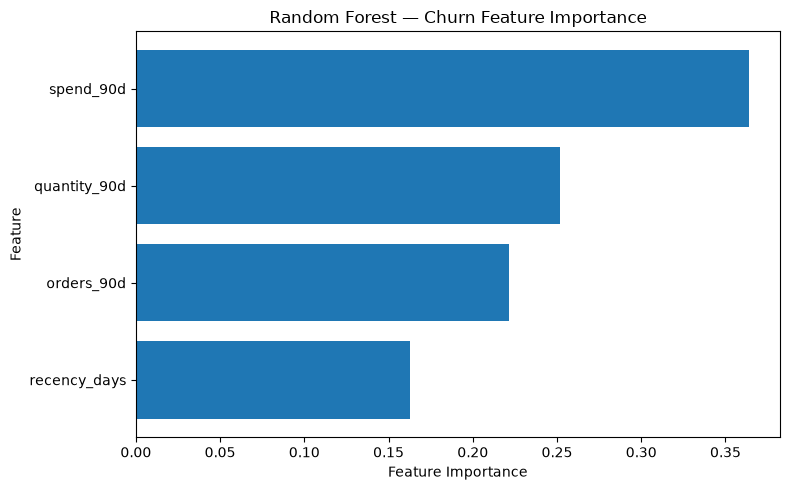

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_final.feature_importances_
}).sort_values("importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Churn Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [24]:
%pip install shap

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\navee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [25]:
import shap
import matplotlib.pyplot as plt

# Explain a sample of the test set
X_explain = X_test.sample(
    n=min(150, len(X_test)),
    random_state=42
)

explainer = shap.TreeExplainer(rf_final)
shap_values = explainer.shap_values(X_explain)

print("SHAP values calculated!")

C:\Users\navee\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP values calculated!


In [26]:
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Class 0 shape:", shap_values[0].shape)
    print("Class 1 shape:", shap_values[1].shape)
else:
    print("SHAP array shape:", shap_values.shape)

SHAP output type: <class 'numpy.ndarray'>
SHAP array shape: (150, 4, 2)


Churn SHAP shape: (150, 4)


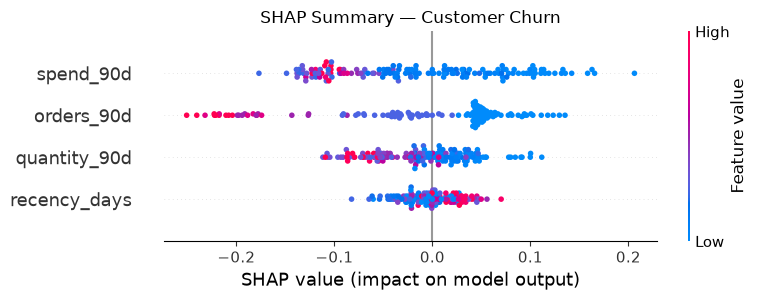

In [27]:
import numpy as np
import shap
import matplotlib.pyplot as plt

# Select SHAP values for class 1: churned
shap_values_churn = shap_values[:, :, 1]

print("Churn SHAP shape:", shap_values_churn.shape)

shap.summary_plot(
    shap_values_churn,
    X_explain,
    feature_names=X_explain.columns,
    show=False
)

plt.title("SHAP Summary — Customer Churn")
plt.tight_layout()
plt.show()

In [28]:
shap_importance = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(shap_values_churn).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(shap_importance.round(4))

,feature,mean_abs_shap
1,spend_90d,0.0755
0,orders_90d,0.0742
2,quantity_90d,0.0403
3,recency_days,0.0219


Customer features:


,orders_90d,spend_90d,quantity_90d,recency_days
1249,1,444.22,274,29


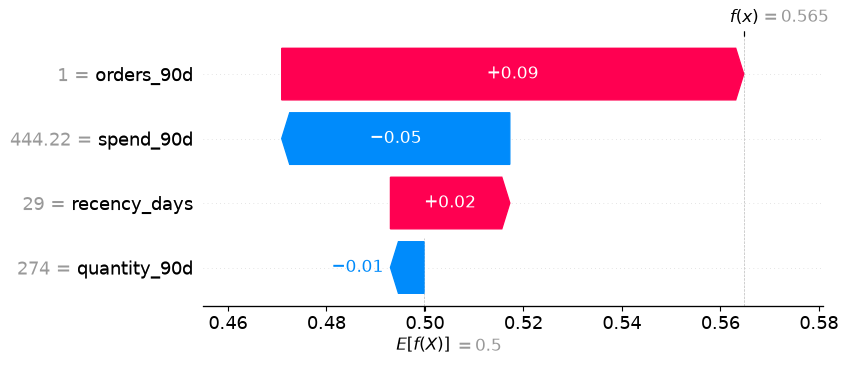

In [29]:
import numpy as np
import shap
import matplotlib.pyplot as plt

# Choose one test customer
customer_index = 0
customer = X_explain.iloc[[customer_index]]

print("Customer features:")
display(customer)

# Get SHAP values for this customer, churn class only
customer_shap = shap_values[customer_index, :, 1]

# Waterfall plot
explanation = shap.Explanation(
    values=customer_shap,
    base_values=explainer.expected_value[1],
    data=customer.iloc[0].values,
    feature_names=customer.columns.tolist()
)

shap.plots.waterfall(explanation)